# 01 — Data inventory, score alignment, and schema checks

**Purpose.** Distinguish the paper's inventory grid from the metadata paired with the saved
score arrays, then inspect the feature-screening rules. No detector is fitted here.

**Inputs** `results/frozen_scores/window_meta_*.parquet` (inventory only),
`results/frozen_scores/score_grid/`, `A_M*_w*.npz`, `data_manifest/`, and the frozen feature list.

**Outputs** `results/regenerated/schema_guard_report.txt` and the inline alignment table.


In [1]:
# Resolve the project root once. Every other path in this notebook is relative to it.
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    # Point PROVICS_ROOT at your checkout, e.g. a clone inside MyDrive.
    os.environ.setdefault('PROVICS_ROOT', '/content/drive/MyDrive/provics-recording-aware-evaluation')
else:
    os.environ.setdefault('PROVICS_ROOT', str(Path.cwd().parent))

sys.path.insert(0, os.environ['PROVICS_ROOT'])
from src.utils.paths import project_root
ROOT = project_root()
print('Project folder:', ROOT.name)

# Render compact, readable tables below each cell.
from IPython.display import display
import pandas as pd
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)


Project folder: code


In [2]:
# Inventory grid used for the dataset description; do not pair it with A_M*_w*.npz.
import pandas as pd
attack = pd.read_parquet(ROOT / 'results/frozen_scores/window_meta_attack22h.parquet')
benign = pd.read_parquet(ROOT / 'results/frozen_scores/window_meta_benign48h.parquet')
print('attack recording windows :', len(attack))
print('benign recording windows :', len(benign))
print('labeled action windows   :', int((attack.label == 1).sum()))
print('\nThe attack recording contains both attack and non-attack periods, which is what makes',
      'the same-recording comparison possible.')
display(pd.DataFrame({'Recording': ['Attack session', 'Benign session'], 'Master-grid windows': [len(attack), len(benign)], 'Action-labeled windows': [int((attack.label == 1).sum()), int((benign.label == 1).sum())]}))


attack recording windows : 1246
benign recording windows : 3117
labeled action windows   : 128

The attack recording contains both attack and non-attack periods, which is what makes the same-recording comparison possible.


,Recording,Master-grid windows,Action-labeled windows
0,Attack session,1246,128
1,Benign session,3117,0


### Match saved scores to their own metadata

The older inventory grid above is retained because it supports the paper's dataset accounting.
Use the metadata below, in their saved row order, with the score arrays at the same resolution.
These files are exact copies from the existing analysis, not regenerated grids.

This checks dimensions and ordering, not detection quality. The per-view availability masks used
for modality-specific AUCs are not supplied, so this is not a complete score-to-AUC reconstruction.


In [3]:
# Check all four modalities at each resolution against the paired metadata.
import numpy as np
from src.evaluation.replay import load_settings
settings = load_settings()
alignment_rows = []
for window in settings['windowing']['durations_seconds']:
    for array_key in ('attack', 'benign'):
        relative = settings['score_metadata'][f'{array_key}_pattern'].format(window_s=window)
        meta = pd.read_parquet(ROOT / relative)
        starts = pd.to_datetime(meta.window_start, utc=True)
        assert starts.is_unique and starts.is_monotonic_increasing
        assert starts.diff().dropna().dt.total_seconds().eq(window).all()
        lengths = []
        for view in ('M1', 'M2', 'M3', 'M4'):
            with np.load(ROOT / f'results/frozen_scores/A_{view}_w{window}.npz') as scores:
                lengths.append(len(scores[array_key]))
                assert len(scores[array_key]) == len(meta), (window, array_key, view)
        alignment_rows.append({'Window (s)': window, 'Recording': array_key,
            'Metadata rows': len(meta), 'Score rows': lengths[0],
            'Views checked': len(lengths), 'Row counts match': all(n == len(meta) for n in lengths)})
display(pd.DataFrame(alignment_rows))
print('All 16 score files match their declared grids for both recording arrays.')


,Window (s),Recording,Metadata rows,Score rows,Views checked,Row counts match
0,5,attack,15121,15121,4,True
1,5,benign,37441,37441,4,True
2,10,attack,7561,7561,4,True
3,10,benign,18721,18721,4,True
4,30,attack,2521,2521,4,True
5,30,benign,6241,6241,4,True
6,60,attack,1261,1261,4,True
7,60,benign,3121,3121,4,True


All 16 score files match their declared grids for both recording arrays.


In [4]:
# The master attack grid omits 15 windows in one telemetry gap; the later analysis
# grid fills that span (1,261 vs 1,246). These metadata are not an alignment map
# for the later score arrays. The benign grids also differ (3,121 vs 3,117).
steps = pd.to_datetime(attack.window_start, utc=True).diff().dropna().dt.total_seconds()
print('distinct step sizes (s):', sorted(steps.unique()))
print('gaps longer than one window:', int((steps > 60).sum()))
print('windows missing in the gap :', int(steps[steps > 60].iloc[0] / 60) - 1)


distinct step sizes (s): [60.0, 960.0]
gaps longer than one window: 1
windows missing in the gap : 15


In [5]:
# Ground-truth events. Labels are used to define positives and to exclude prior attack
# windows from the reference set. They are never a model input.
events = pd.read_csv(ROOT / 'data_manifest/ground_truth_events.csv', parse_dates=['start','end'])
print('labeled attack actions:', len(events))
campaigns = events.groupby('campaign_id').agg(events=('event_id','size'),
                                             seconds=('duration_s','sum'))
display(campaigns)


labeled attack actions: 32


,events,seconds
campaign_id,,
C1,6,368.187
C2,9,2309.872
C3,6,1063.017
C4,11,2482.288


### Labeled actions by campaign

These are counts from the ground-truth event file, not detector results. The campaigns are the temporal groups used in the paper.


Matplotlib is building the font cache; this may take a moment.


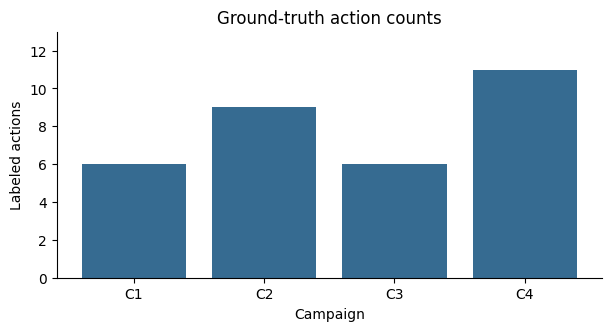

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.2), layout='constrained')
ax.bar(campaigns.index.astype(str), campaigns['events'], color='#366b91')
ax.set(xlabel='Campaign', ylabel='Labeled actions', title='Ground-truth action counts')
ax.set_ylim(0, campaigns['events'].max() + 2)
ax.spines[['top', 'right']].set_visible(False)
plt.show()
plt.close(fig)

In [7]:
# The leakage guard. It rejects ground truth, partition fields, raw identifiers, timestamps
# and availability indicators. Availability is rejected because view presence is itself a
# recording property: M2 is present in 77.6% of windows against 94.9% for M1 and M3.
from src.data.schema_guard import inspect
candidate = ['m3_n', 'm3_dt_mean', 'm1_outdeg_mean', 'm4_LevelPV__mean',
             'label', 'src_port', 'dst_ip', 'proc_pid', 'window_start', 'm1__present']
report = inspect(candidate)
print(report.to_text('illustrative matrix'))
display(pd.DataFrame({'Candidate column': candidate, 'Decision': ['reject' if name in report.rejected else 'allow' for name in candidate], 'Reason': [report.rejected.get(name, 'aggregate feature') for name in candidate]}))


schema guard — illustrative matrix
  allowed  : 4
  rejected : 6
  exempted : 0
    REJECT  dst_ip  [network_identifier]
    REJECT  label  [ground_truth]
    REJECT  m1__present  [availability]
    REJECT  proc_pid  [host_identifier]
    REJECT  src_port  [network_identifier]
    REJECT  window_start  [time]


,Candidate column,Decision,Reason
0,m3_n,allow,aggregate feature
1,m3_dt_mean,allow,aggregate feature
2,m1_outdeg_mean,allow,aggregate feature
3,m4_LevelPV__mean,allow,aggregate feature
4,label,reject,ground_truth
5,src_port,reject,network_identifier
6,dst_ip,reject,network_identifier
7,proc_pid,reject,host_identifier
8,window_start,reject,time
9,m1__present,reject,availability


In [8]:
# Run the guard over the exact feature list used for the paper.
import json
listing = json.loads((ROOT / 'configs/frozen_specs/feature_lists_post_screening.json').read_text())
columns = [c for key, value in listing.items() if key != '_meta' for c in value['features']]
report = inspect(columns)
print(f'paper feature columns : {len(columns)}')
print(f'rejected              : {len(report.rejected)}')
print(f'documented exemptions : {len(set(report.exempted))}')
for column in sorted(set(report.exempted)):
    print('   ', column)

out = ROOT / 'results/regenerated'; out.mkdir(parents=True, exist_ok=True)
path = out / 'schema_guard_report.txt'
path.write_text(report.to_text('paper feature list'))
print('\nwrote', path.relative_to(ROOT))


paper feature columns : 2100
rejected              : 0
documented exemptions : 8
    m1_subtypes_file
    m1_subtypes_file__frac
    m2_pnames_sshd-session
    m2_subtypes_file
    m2_subtypes_file__frac
    m3_n_client_ports
    m3_tid_reset_frac
    m3_tid_span

wrote results/regenerated/schema_guard_report.txt


### Why M3 is a reduced-input view

The released ProvICS records carry no Modbus register-value field, so M3 summarises protocol
semantics — function codes, register-reference statistics, read/write behaviour and timing —
rather than payload values. This is a property of the release, not a modelling choice.


## What this notebook established

- The grid holds 1,246 attack and 3,117 benign windows with 128 labeled action windows.
- The single 960 s gap accounts for the 15-window difference between the two grids.
- The guard rejects every banned field and accepts all 2,100 real feature columns, with
  eight documented exemptions that are aggregate statistics rather than identifiers.
- Each released score array has a matching, separately named score-grid metadata file.
